# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [43]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [11]:
df = pd.read_csv("AviationData_Cleaned.csv", low_memory=False)


In [12]:
df["Event.Date"] = pd.to_datetime(df["Event.Date"], errors="coerce")
df = df[df["Year"] >= 1983].copy()

In [13]:
df["Amateur.Built"] = df["Amateur.Built"].fillna("NO").str.upper()
df = df[df["Amateur.Built"] == "NO"].copy()

In [14]:
df["Total.occupants"] = pd.to_numeric(df["Total.occupants"], errors="coerce").fillna(0)
df["Fatal.Serious.Count"] = pd.to_numeric(df["Fatal.Serious.Count"], errors="coerce").fillna(0)
df["Destroyed.Flag"] = pd.to_numeric(df["Destroyed.Flag"], errors="coerce").fillna(0)

In [15]:
df["fatal_serious_fraction"] = np.where(
    df["Total.occupants"] > 0,
    df["Fatal.Serious.Count"] / df["Total.occupants"],
    np.nan
)

In [16]:
print(df.head())
print(df.shape)
print(df.isna().sum().sort_values(ascending=False).head(20))
print(df.dtypes)

         Event.Id Investigation.Type Accident.Number Event.Date  \
0  20001214X42095           Accident      SEA83LA036 1983-01-01   
1  20001214X42067           Accident      MKC83LA056 1983-01-01   
2  20001214X42063           Accident      MKC83LA050 1983-01-01   
3  20001214X42018           Accident      LAX83FUG11 1983-01-01   
4  20001214X41951           Accident      CHI83LA074 1983-01-01   

          Location        Country Latitude Longitude Airport.Code  \
0      NEWPORT, OR  United States      NaN       NaN          ONP   
1     WOODBINE, IA  United States      NaN       NaN          3YR   
2    MARYVILLE, MO  United States      NaN       NaN          78Y   
3       UPLAND, CA  United States      NaN       NaN          CCB   
4  SPRINGBROOK, WI  United States      NaN       NaN          NaN   

        Airport.Name  ... Publication.Date  Year Total.occupants  \
0  NEWPORT MUNICIPAL  ...              NaN  1983               4   
1          MUNICIPAL  ...              NaN  19

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [18]:
threshold = 20

small = df[df["Total.occupants"] < threshold].copy()
large = df[df["Total.occupants"] >= threshold].copy()

print("Small aircraft rows:", len(small))
print("Large aircraft rows:", len(large))

Small aircraft rows: 72289
Large aircraft rows: 1529


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [19]:
def make_summary(group):
    out = (
        group.groupby("Make")
        .agg(
            n=("Event.Id", "size"),
            mean_fatal_serious=("fatal_serious_fraction", "mean"),
            destroyed_fraction=("Destroyed.Flag", "mean"),
            mean_occupants=("Total.occupants", "mean")
        )
        .reset_index()
        .dropna(subset=["mean_fatal_serious"])
        .query("n >= 10")
        .sort_values("mean_fatal_serious")
    )
    return out

small_makes = make_summary(small).head(15)
large_makes = make_summary(large).head(15)

print("Smallest mean fatal/serious injury makes (small aircraft):")
print(small_makes.head(15).to_string(index=False))

print("\nSmallest mean fatal/serious injury makes (large aircraft):")
print(large_makes.head(15).to_string(index=False))

Smallest mean fatal/serious injury makes (small aircraft):
                       Make   n  mean_fatal_serious  destroyed_fraction  mean_occupants
           Cub Crafters Inc  20            0.050000            0.000000        1.650000
American Legend Aircraft Co  17            0.058824            0.000000        1.411765
                       Snow  28            0.071429            0.107143        1.107143
     Classic Aircraft Corp.  16            0.083333            0.062500        2.500000
        Meyers Aircraft Co.  10            0.100000            0.100000        1.700000
     Evektor-Aerotechnik As  30            0.100000            0.000000        1.400000
                       Waco 138            0.102657            0.086957        2.050725
                 Bombardier  22            0.103846            0.045455        3.409091
          Grumman-Schweizer 126            0.104497            0.253968        1.031746
           Dassault-Breguet  18            0.138889          

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

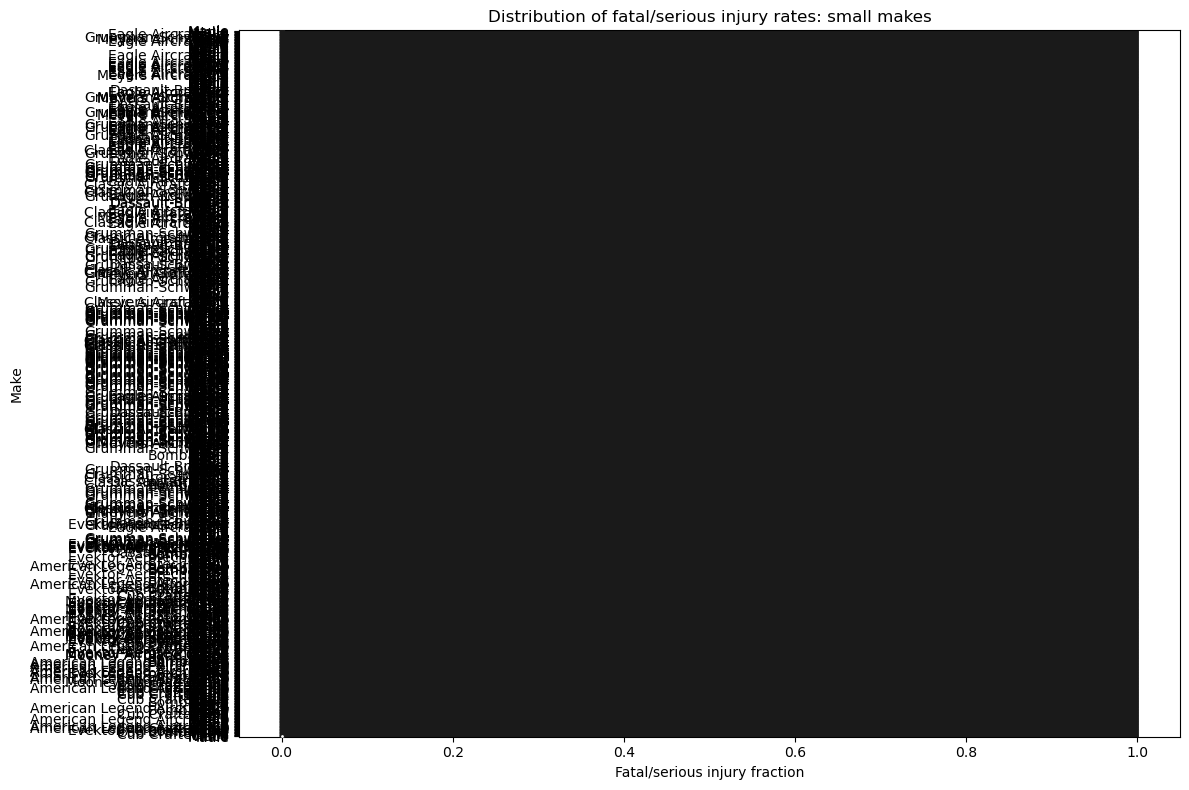

In [44]:
small_violin_df = small[small["Make"].isin(small_makes["Make"])].copy()

plt.figure(figsize=(12, 8))
sns.violinplot(
    data=small_violin_df,
    x="fatal_serious_fraction",
    y="Make",
    order=small_makes["Make"],
    orient="h",
    cut=0,
    inner="box",
    palette="viridis"
)
plt.title("Distribution of fatal/serious injury rates: small makes")
plt.xlabel("Fatal/serious injury fraction")
plt.ylabel("Make")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

c:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


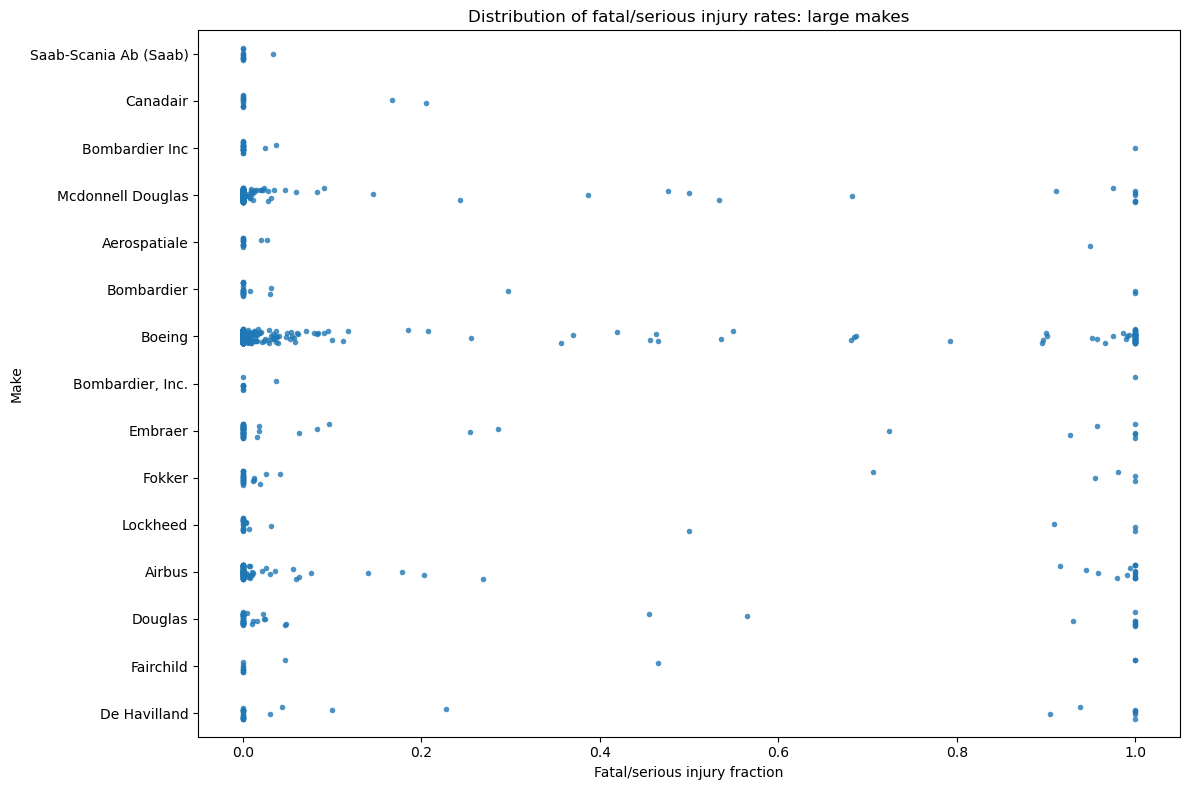

In [24]:
large_strip_df = large[large["Make"].isin(large_makes["Make"])].copy()

plt.figure(figsize=(12, 8))
sns.stripplot(
    data=large_strip_df,
    x="fatal_serious_fraction",
    y="Make",
    order=large_makes["Make"],
    dodge=False,
    jitter=0.15,
    alpha=0.8,
    size=4
)
plt.title("Distribution of fatal/serious injury rates: large makes")
plt.xlabel("Fatal/serious injury fraction")
plt.ylabel("Make")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [26]:
destroyed_by_make = (
    df.groupby("Make")
    .agg(
        n=("Event.Id", "size"),
        destroyed_fraction=("Destroyed.Flag", "mean"),
        mean_fatal_serious=("fatal_serious_fraction", "mean")
    )
    .reset_index()
    .query("n >= 10")
    .sort_values(["destroyed_fraction", "mean_fatal_serious"])
    .head(15)
)

print("Lowest aircraft destruction rates by make:")
print(destroyed_by_make.to_string(index=False))

Lowest aircraft destruction rates by make:
                          Make  n  destroyed_fraction  mean_fatal_serious
              Cub Crafters Inc 20            0.000000            0.050000
   American Legend Aircraft Co 17            0.000000            0.058824
        Evektor-Aerotechnik As 30            0.000000            0.100000
        Mooney Airplane Co Inc 10            0.000000            0.150000
                  Cub Crafters 18            0.000000            0.166667
                      Stearman 27            0.000000            0.203704
               Cubcrafters Inc 21            0.000000            0.214286
           Remos Aircraft Gmbh 13            0.000000            0.230769
             Universal Stinson 11            0.000000            0.242424
     Burkhart Grob Flugzeugbau 15            0.000000            0.300000
                      Centrair 12            0.000000            0.333333
       Christen Industries Inc 16            0.000000            0.43

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

"""

The safest make groups are those with both:
- a low mean fatal/serious injury fraction
- a low destroyed fraction
- enough observations to avoid unstable estimates

Because we filtered to professionally built aircraft and years from 1983 onward, the comparisons are more relevant to modern active fleets.
For smaller aircraft, a low mean fatal/serious injury fraction is often driven by a combination of lower occupancy, lower operating complexity, and better maintenance practices.
For larger aircraft, the safest makes should not just have low injury rates but also low destruction rates, since even a few severe accidents can dominate the risk profile.

When comparing makes, the most useful signal is not a single extreme value but the combination of:
1. the average fatal/serious injury fraction,
2. the destroyed fraction,
3. the sample size.

This ensures the recommendation is statistically robust rather than based on tiny sample sizes.

"""

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

In [29]:
# Filter plane types 
plane_type_summary = (
    df.groupby("Plane.Type")
    .agg(
        n=("Event.Id", "size"),
        mean_fatal_serious=("fatal_serious_fraction", "mean"),
        destroyed_fraction=("Destroyed.Flag", "mean")
    )
    .reset_index()
    .query("n >= 10")
    .sort_values("mean_fatal_serious")
)

print(plane_type_summary.head(15).to_string(index=False))

                       Plane.Type  n  mean_fatal_serious  destroyed_fraction
                   Boeing 757-232 10            0.000000            0.000000
Diamond Aircraft Ind Inc DA 20 C1 11            0.000000            0.000000
                       Bell 47D-1 10            0.000000            0.000000
                    Ayres S2R-G10 12            0.000000            0.166667
                 Piper PA-18A 150 12            0.000000            0.000000
                       Boeing 777 42            0.000000            0.023810
                   Boeing 757-222 10            0.000000            0.000000
                    Grumman G164B 16            0.000000            0.062500
                      Cessna 180C 15            0.000000            0.066667
         Mcdonnell Douglas MD-11F 10            0.000000            0.100000
          Mcdonnell Douglas MD-83 14            0.000938            0.071429
          Mcdonnell Douglas MD-80 11            0.000978            0.000000

**Larger planes**

In [30]:
large_plane_types = (
    large.groupby("Plane.Type")
    .agg(
        n=("Event.Id", "size"),
        mean_fatal_serious=("fatal_serious_fraction", "mean"),
        destroyed_fraction=("Destroyed.Flag", "mean")
    )
    .reset_index()
    .query("n >= 10")
    .sort_values("mean_fatal_serious")
)

print("Larger plane types sorted by lowest fatal/serious injury ratio:")
print(large_plane_types.head(15).to_string(index=False))


Larger plane types sorted by lowest fatal/serious injury ratio:
                Plane.Type  n  mean_fatal_serious  destroyed_fraction
                Boeing 777 18            0.000000            0.055556
            Boeing 757-232 10            0.000000            0.000000
            Boeing 757-222 10            0.000000            0.000000
   Mcdonnell Douglas MD-83 13            0.000938            0.076923
   Mcdonnell Douglas MD-80 11            0.000978            0.000000
   Mcdonnell Douglas MD-88 17            0.003247            0.000000
Bombardier Inc CL-600-2B19 11            0.005640            0.000000
 Mcdonnell Douglas DC-9-51 11            0.005693            0.090909
Mcdonnell Douglas DC-10-30 12            0.008389            0.083333
                Boeing 747 10            0.009542            0.000000
   Mcdonnell Douglas MD-11 15            0.020426            0.066667
      Canadair CL-600-2B19 10            0.020513            0.000000
            Boeing 727-232

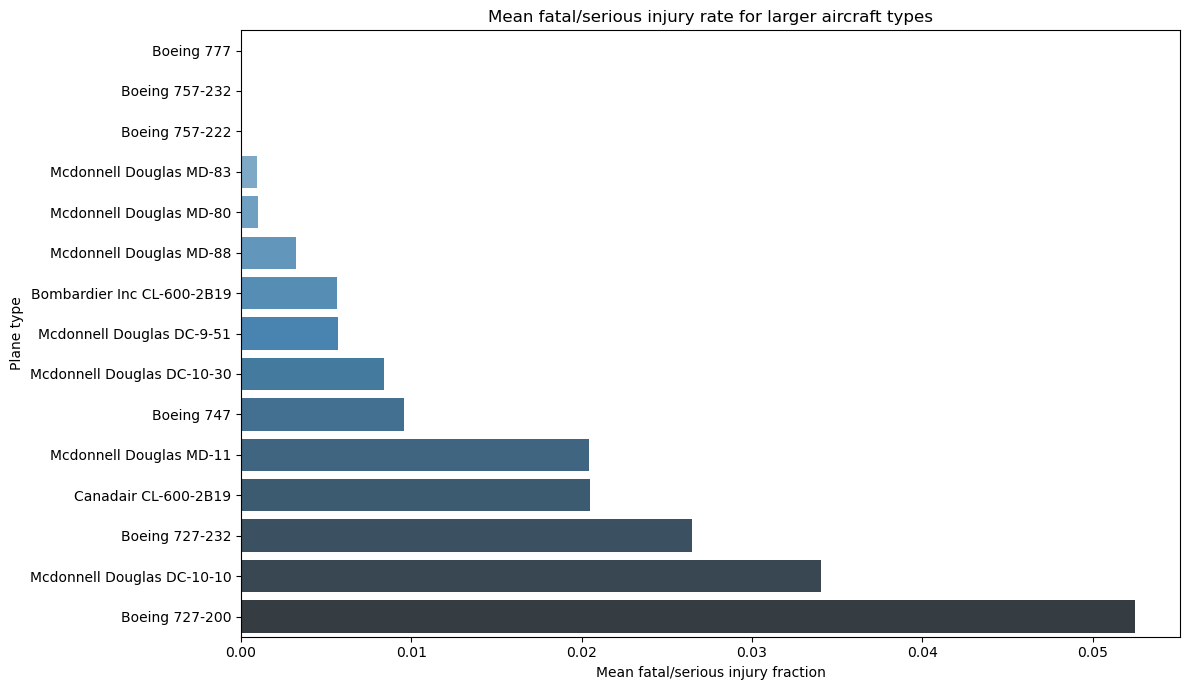

In [31]:
plt.figure(figsize=(12, 7))
sns.barplot(
    data=large_plane_types.head(15),
    x="mean_fatal_serious",
    y="Plane.Type",
    orient="h",
    palette="Blues_d"
)
plt.title("Mean fatal/serious injury rate for larger aircraft types")
plt.xlabel("Mean fatal/serious injury fraction")
plt.ylabel("Plane type")
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [32]:
small_plane_types = (
    small.groupby("Plane.Type")
    .agg(
        n=("Event.Id", "size"),
        mean_fatal_serious=("fatal_serious_fraction", "mean"),
        destroyed_fraction=("Destroyed.Flag", "mean")
    )
    .reset_index()
    .query("n >= 10")
    .sort_values("mean_fatal_serious")
)

print("Smaller plane types sorted by lowest fatal/serious injury ratio:")
print(small_plane_types.head(15).to_string(index=False))

Smaller plane types sorted by lowest fatal/serious injury ratio:
                       Plane.Type  n  mean_fatal_serious  destroyed_fraction
                    Grumman G164B 16            0.000000            0.062500
                    Ayres S2R-G10 12            0.000000            0.166667
                 Piper PA-18A 150 12            0.000000            0.000000
Diamond Aircraft Ind Inc DA 20 C1 11            0.000000            0.000000
                      Cessna 180C 15            0.000000            0.066667
                       Boeing 777 24            0.000000            0.000000
                       Bell 47D-1 10            0.000000            0.000000
                   Maule MX-7-235 17            0.029412            0.000000
               Burkhart Grob G103 15            0.033333            0.000000
         Grumman-Schweizer G-164A 49            0.034014            0.163265
                     Hiller UH12E 13            0.038462            0.153846
           

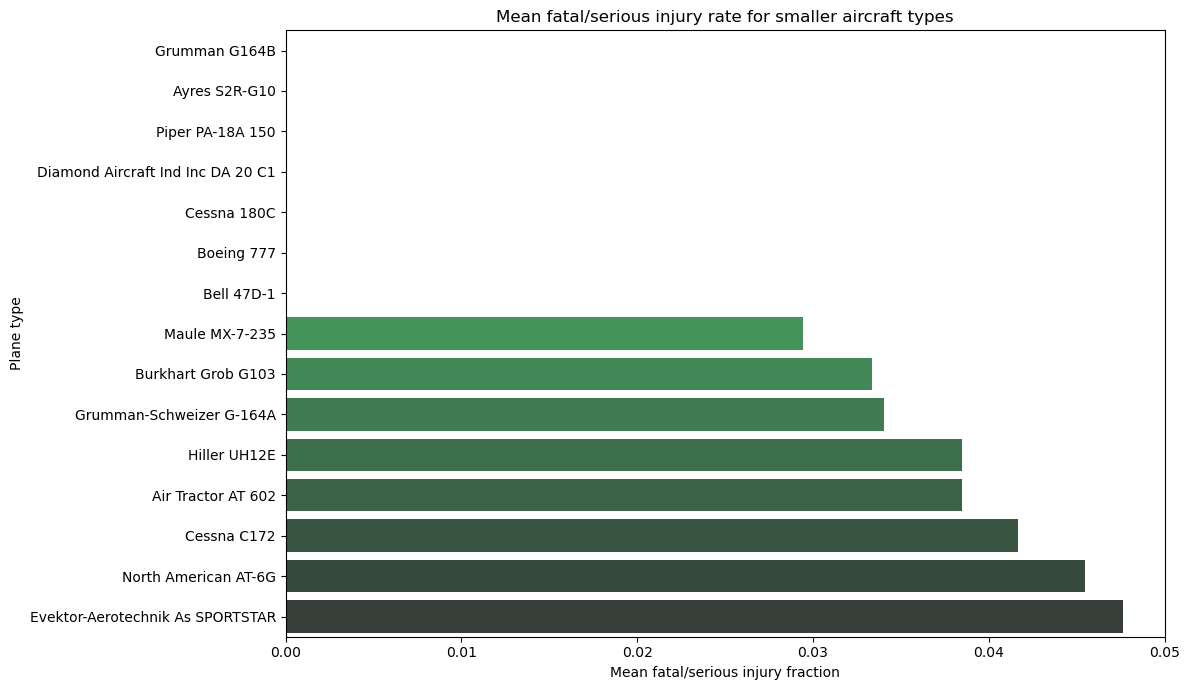

In [33]:
plt.figure(figsize=(12, 7))
sns.barplot(
    data=small_plane_types.head(15),
    x="mean_fatal_serious",
    y="Plane.Type",
    orient="h",
    palette="Greens_d"
)
plt.title("Mean fatal/serious injury rate for smaller aircraft types")
plt.xlabel("Mean fatal/serious injury fraction")
plt.ylabel("Plane type")
plt.tight_layout()
plt.show()

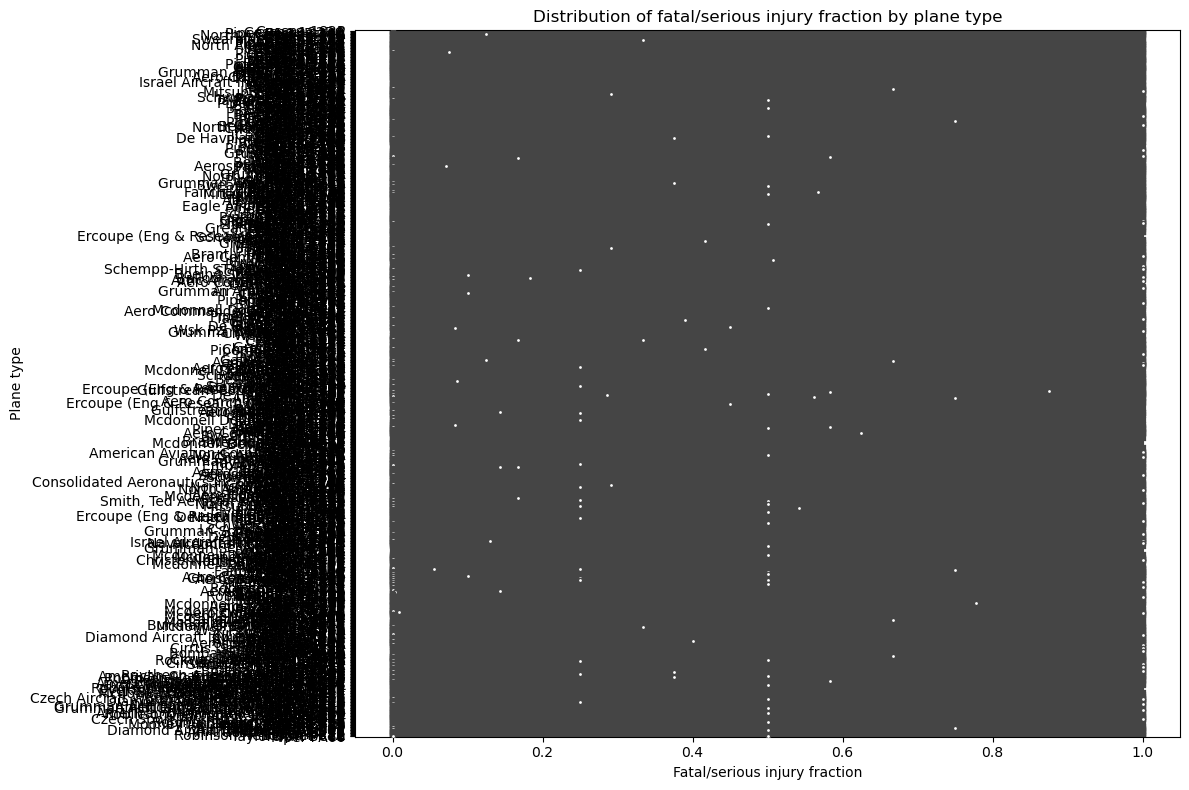

In [42]:
# Distributional plot by plane type
plot_plane_types = (
    df[df["Plane.Type"].isin(
        plane_type_summary[plane_type_summary["n"] >= 10]["Plane.Type"]
    )]
    .copy()
)

plt.figure(figsize=(12, 8))
sns.violinplot(
    data=plot_plane_types,
    x="fatal_serious_fraction",
    y="Plane.Type",
    orient="h",
    cut=0,
    inner="box"
)
plt.title("Distribution of fatal/serious injury fraction by plane type")
plt.xlabel("Fatal/serious injury fraction")
plt.ylabel("Plane type")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

"""

For plane-type comparisons, the key is not just the average fatal/serious injury rate but also how concentrated the risk is.
A low mean with a wide spread suggests that some aircraft in the type are very risky, while others are safe.

In general:
- larger aircraft types tend to show lower variance in serious injury rates when they are well-maintained and operated under routine conditions,
- smaller aircraft types can show much wider dispersion because they appear in many different operational contexts and are more sensitive to weather and pilot decision-making.

To make strong recommendations, we should focus on plane types that have:
- enough examples to support a stable estimate,
- low mean fatal/serious injury fraction,
- low destruction rates,
- consistent performance across multiple incidents rather than one lucky outlier.

"""

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [36]:
#Weather Condition

weather_summary = (
    df.groupby("Weather.Condition")
    .agg(
        n=("Event.Id", "size"),
        mean_fatal_serious=("fatal_serious_fraction", "mean"),
        destroyed_fraction=("Destroyed.Flag", "mean")
    )
    .reset_index()
    .query("n >= 20")
    .sort_values("mean_fatal_serious")
)

print("Weather condition comparison:")
print(weather_summary.to_string(index=False))

Weather condition comparison:
Weather.Condition     n  mean_fatal_serious  destroyed_fraction
              VMC 64451            0.234584            0.170548
          Unknown  3185            0.532865            0.290738
              UNK   672            0.611726            0.592262
              IMC  5306            0.658434            0.578213
              Unk   204            0.670938            0.352941


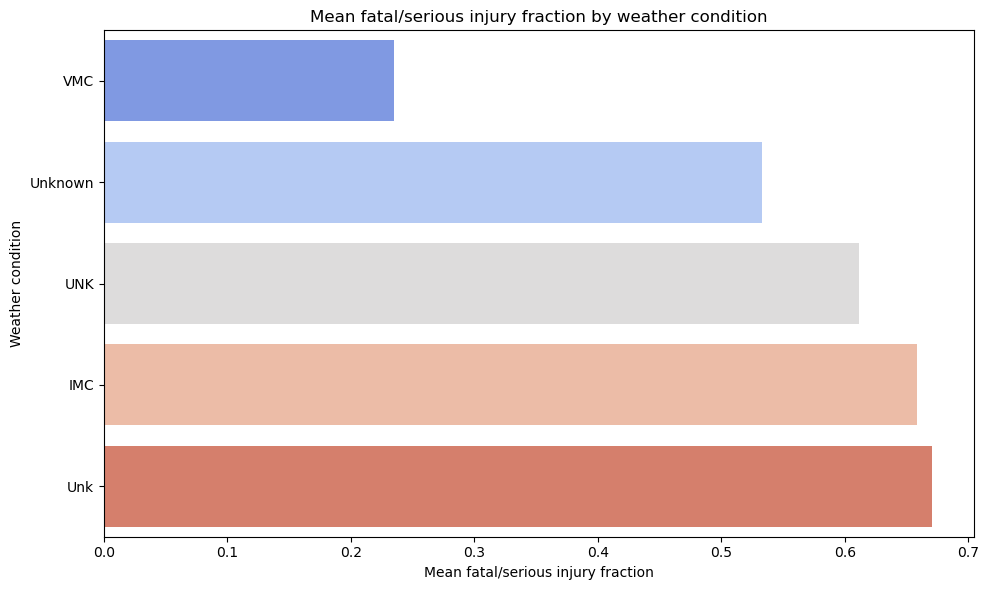

In [37]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=weather_summary,
    x="mean_fatal_serious",
    y="Weather.Condition",
    orient="h",
    palette="coolwarm"
)
plt.title("Mean fatal/serious injury fraction by weather condition")
plt.xlabel("Mean fatal/serious injury fraction")
plt.ylabel("Weather condition")
plt.tight_layout()
plt.show()

In [38]:
#Phase of Flight
phase_summary = (
    df.groupby("Broad.phase.of.flight")
    .agg(
        n=("Event.Id", "size"),
        mean_fatal_serious=("fatal_serious_fraction", "mean"),
        destroyed_fraction=("Destroyed.Flag", "mean")
    )
    .reset_index()
    .query("n >= 20")
    .sort_values("mean_fatal_serious")
)

print("Phase-of-flight comparison:")
print(phase_summary.to_string(index=False))

Phase-of-flight comparison:
Broad.phase.of.flight     n  mean_fatal_serious  destroyed_fraction
                 Taxi  1655            0.019325            0.028399
              Landing 13392            0.041338            0.045998
             Standing   706            0.094320            0.131728
              Takeoff 10202            0.231067            0.218683
            Go-around  1212            0.302730            0.292904
              Descent  1515            0.325876            0.312871
             Approach  5385            0.343493            0.288951
               Cruise  8475            0.349140            0.338997
              Unknown 22827            0.358771            0.159723
                Other    86            0.399529            0.313953
                Climb  1628            0.408788            0.403563
          Maneuvering  6735            0.474148            0.427765


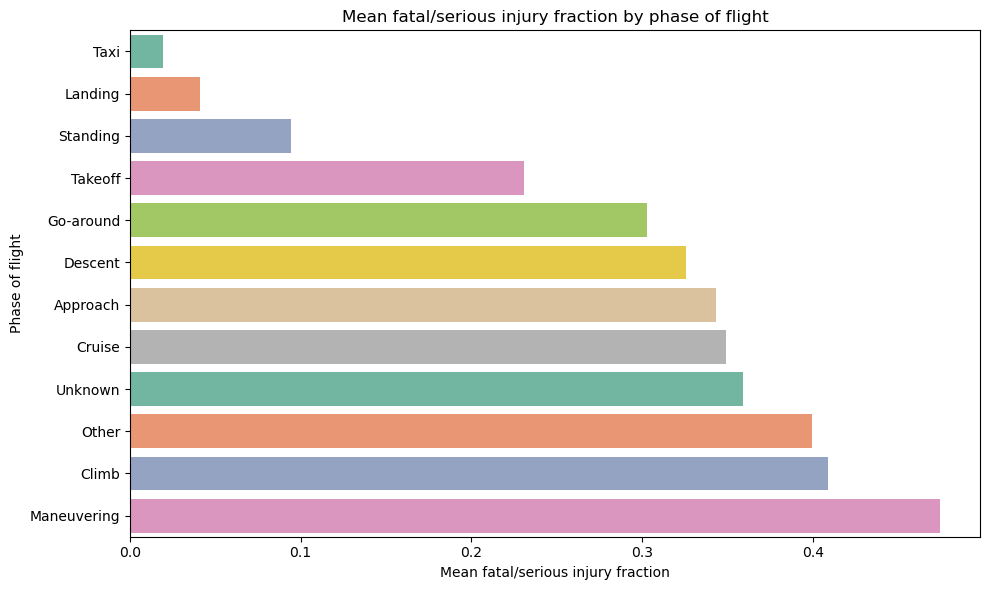

In [39]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=phase_summary,
    x="mean_fatal_serious",
    y="Broad.phase.of.flight",
    orient="h",
    palette="Set2"
)
plt.title("Mean fatal/serious injury fraction by phase of flight")
plt.xlabel("Mean fatal/serious injury fraction")
plt.ylabel("Phase of flight")
plt.tight_layout()
plt.show()

#
"""

Two of the most informative variables in this dataset are weather and phase of flight.

Weather:
- VMC conditions tend to be less severe than IMC (instrument meteorological conditions), but the real risk is driven by the combination of poor visibility and operational complexity.
- If a weather group has both a higher mean fatal/serious injury fraction and a higher destroyed fraction, it is likely a meaningful safety risk.
- This matters because pilots may be more exposed to poor decision-making under degraded visibility.

Phase of flight:
- Takeoff, climb, landing, and approach phases often have much higher risk than cruise.
- These phases are short but operationally demanding, with limited time to recover from a problem.
- A higher mean fatal/serious fraction in a phase such as approach or landing suggests that accident severity is heavily shaped by the operational environment, not just aircraft design.

Together, these factors show that safety is not driven by make alone. Exposure context matters: weather, phase of flight, and operating conditions often explain a substantial share of injury severity.

"""

In [41]:
#recommendation

small_makes_summary = make_summary(df[df["Total.occupants"] < threshold])
large_makes_summary = make_summary(df[df["Total.occupants"] >= threshold])

safe_small = small_makes_summary.head(10)
safe_large = large_makes_summary.head(10)

print("Recommended safe small makes:")
print(safe_small[["Make", "mean_fatal_serious", "destroyed_fraction", "n"]].to_string(index=False))

print("\nRecommended safe large makes:")
print(safe_large[["Make", "mean_fatal_serious", "destroyed_fraction", "n"]].to_string(index=False))

Recommended safe small makes:
                       Make  mean_fatal_serious  destroyed_fraction   n
           Cub Crafters Inc            0.050000            0.000000  20
American Legend Aircraft Co            0.058824            0.000000  17
                       Snow            0.071429            0.107143  28
     Classic Aircraft Corp.            0.083333            0.062500  16
        Meyers Aircraft Co.            0.100000            0.100000  10
     Evektor-Aerotechnik As            0.100000            0.000000  30
                       Waco            0.102657            0.086957 138
                 Bombardier            0.103846            0.045455  22
          Grumman-Schweizer            0.104497            0.253968 126
           Dassault-Breguet            0.138889            0.166667  18

Recommended safe large makes:
                 Make  mean_fatal_serious  destroyed_fraction   n
Saab-Scania Ab (Saab)            0.002778            0.000000  12
             Ca